# MODULE 23 — TRANSFORMER ARCHITECTURE

## 1. Why Transformers?

Transformers were introduced to overcome important limitations of recurrent sequence models such as RNNs.

The key shift is:

```text
RNN
↓
Sequential computation
↓
Hidden-state propagation
```

versus:

```text
Transformer
↓
Attention-based computation
↓
Parallel processing during training
```

---

## 2. RNN-Based Sequence Processing

An RNN processes tokens sequentially.

```text
x₁ → RNN → h₁
          ↓
x₂ → RNN → h₂
          ↓
x₃ → RNN → h₃
          ↓
x₄ → RNN → h₄
          ↓
...
```

The hidden state is computed as:

$$
h_t = f(x_t, h_{t-1})
$$

Therefore, the computation at timestep \(t\) depends on the previous timestep.

### Example

For:

```text
"The cat sat on the mat"
```

the processing is conceptually:

```text
The → cat → sat → on → the → mat
```

The model must process the sequence step by step.

---

## 3. Sequential Computation Problem

The sequential dependency of RNNs makes parallel computation difficult.

```text
x₁
 ↓
h₁
 ↓
h₂
 ↓
h₃
 ↓
h₄
 ↓
...
```

For example, \(h_4\) cannot be computed until \(h_3\) is available.

This limits how effectively the model can exploit the parallel computational capabilities of modern GPUs.

---

## 4. Transformer-Based Processing

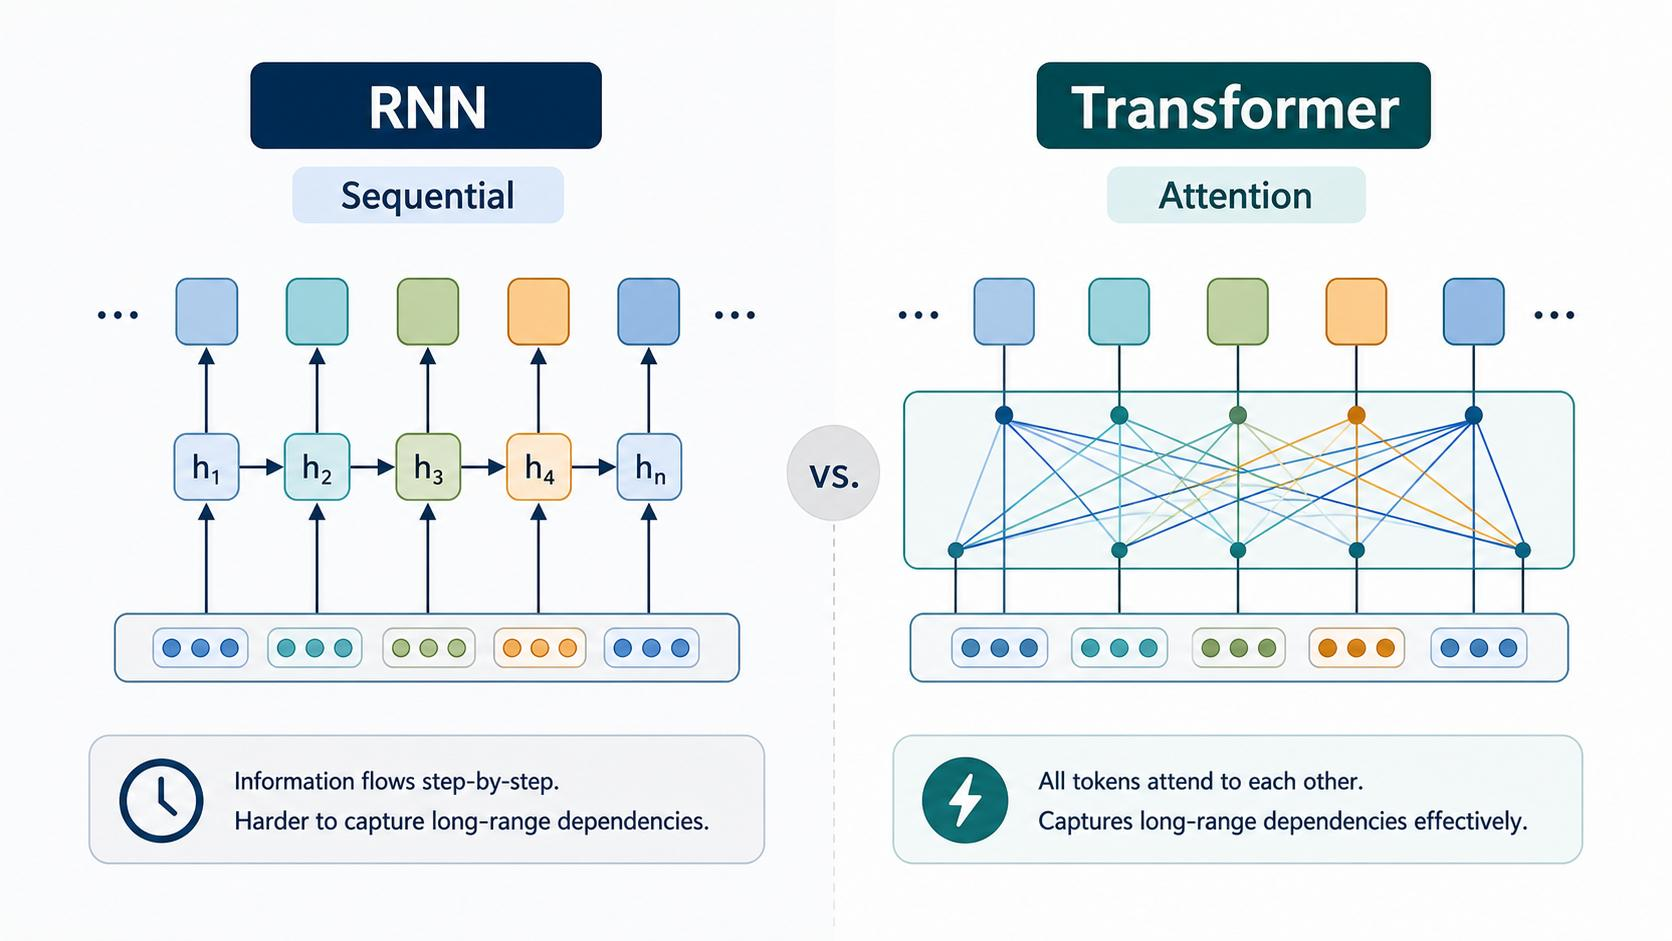

Transformers replace recurrent processing with **attention-based processing**.

```text
x₁   x₂   x₃   x₄   ...   xₙ
 \    |    |    |          /
  \   |    |    |         /
       Self-Attention
              ↓
   Contextual representations
```

Instead of passing information through a sequence of recurrent hidden states, tokens can directly interact through attention.

The central idea is:

> **Attention allows each token to use information from other relevant tokens when constructing its representation.**



---

## 5. Why Attention Helps

Consider:

> **"The animal didn't cross the road because it was tired."**

The representation of `"it"` may need information from `"animal"`.

With attention:

```text
"it" ───────────────→ "animal"
```

Tokens can establish direct relationships with other tokens.

This is different from relying on information being passed through a long chain of recurrent states.

---

## 6. RNN vs Transformer

| Property | RNN | Transformer |
|---|---|---|
| Core mechanism | Recurrence | Attention |
| Computation | Sequential | Highly parallelizable during training |
| Information flow | Hidden states | Attention connections |
| Long-range interaction | Through recurrent states | Direct through attention |
| GPU parallelism | Limited by sequential dependency | Much better suited to parallel computation |
| Positional information | Sequence order comes through recurrence | Must be explicitly represented |
| Main operations | Hidden-state updates | Attention + Feed-Forward Network |

---

## 7. Why Parallelism Matters

Consider:

```text
"The quick brown fox jumps over the lazy dog"
```

### RNN

```text
t₁ → t₂ → t₃ → t₄ → t₅ → t₆ → t₇ → t₈ → t₉
```

The sequence contains sequential dependencies.

### Transformer

The attention computation can operate over the sequence using large tensor operations:

```text
t₁   t₂   t₃   t₄   t₅   t₆   t₇   t₈   t₉
 \    |    |    |    |    |    |    |    /
              ↓
       Self-Attention
              ↓
    Contextual representations
```

This is highly compatible with GPU parallelism.

---

## 8. Important Nuance: Transformers Are Not Completely Parallel

Do **not** say:

> "Transformers are completely parallel."

A more accurate statement is:

> **Transformers are highly parallelizable during training, but autoregressive generation is still sequential across generation steps.**

### Training

The complete input sequence is known:

```text
The cat sat on the mat
```

Many operations can be computed in parallel.

### Autoregressive generation

When generating text:

```text
The
 ↓
The cat
 ↓
The cat sat
 ↓
The cat sat on
```

the next token depends on previously generated tokens.

Therefore:

```text
token₁ → token₂ → token₃ → token₄
```

remains sequential across generation steps.

---

## 9. The Core Architectural Shift

### RNN

```text
Sequence
   ↓
Recurrence
   ↓
Hidden State
   ↓
Next Token
   ↓
Next Hidden State
```

### Transformer

```text
Sequence
   ↓
Token Representations
   ↓
Self-Attention
   ↓
Information Exchange
   ↓
Feed-Forward Network
   ↓
Contextual Representations
```

Therefore, a Transformer is **not simply a faster RNN**.

It is a fundamentally different architecture based on attention.

---

## 10. Attention from Module 22

The scaled dot-product attention mechanism is:

$$
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}
\right)V
$$

The important architectural consequence is:

> **Each token can construct its representation using information from other tokens.**

This enables direct token-to-token interaction.

---

## 11. Positional Information

Attention by itself does not inherently encode the order of tokens.

Consider:

```text
"The dog bites the man"
```

and:

```text
"The man bites the dog"
```

The same words are present, but their order changes the meaning.

Therefore, Transformers need **positional information**.

Conceptually:

```text
Token Embedding
      +
Positional Information
      ↓
Transformer
```

Positional information allows the model to distinguish different token positions.

---

## 12. Computational Trade-off

Self-attention computes:

$$
QK^T
$$

If the sequence length is \(n\), the resulting attention score matrix has shape:

$$
n \times n
$$

Therefore, standard self-attention has a quadratic dependence on sequence length for its pairwise token interactions.

```text
Sequence length ↑
        ↓
Attention matrix
        ↓
     n × n
        ↓
Memory / computation ↑
```

This becomes an important limitation when processing very long sequences.

---

## 13. Transformer Model Families

The Transformer architecture later led to several important model configurations:

```text
                    Transformer
                         │
          ┌──────────────┼──────────────┐
          ↓              ↓              ↓
    Encoder-only    Decoder-only   Encoder-Decoder
          │              │              │
        BERT         GPT-style        T5
```

### Encoder-only

Primarily used for understanding tasks such as:

- Classification
- NER
- Token classification
- Sentence representations

### Decoder-only

Primarily used for autoregressive generation.

### Encoder-decoder

Useful for sequence-to-sequence tasks such as:

- Machine translation
- Summarization
- Text transformation

The syllabus later covers BERT, summarization, and machine translation. 

---

## 14. Why Transformers Became Important

The Transformer architecture provides:

1. **Direct token-to-token interaction**
2. **Better handling of long-range relationships**
3. **Highly parallelizable training**
4. **Efficient utilization of modern GPUs**
5. **A scalable architecture for large NLP models**

The original Transformer architecture forms the foundation for much of modern NLP.

---

# Interview Perspective

### Question: Why were Transformers introduced?

**Answer:**

> Transformers replaced recurrent sequential processing with attention-based processing. Attention allows tokens to directly interact with one another, while removing recurrence makes the computation highly parallelizable during training and better suited to modern GPU hardware.

### Avoid saying:

> "Transformers are just faster RNNs."

### Better:

> "Transformers use a fundamentally different attention-based mechanism instead of recurrent hidden-state propagation."

---

# Key Mental Model

```text
RNN
│
├── Sequential processing
├── Recurrence
├── Hidden-state propagation
└── Limited parallelism


Transformer
│
├── Attention
├── Direct token interaction
├── Parallelizable training
└── Contextual representations
```

---

# What You Should Remember

1. **RNNs use recurrence; Transformers use attention.**
2. RNN computation is inherently sequential.
3. Transformers are highly parallelizable during training.
4. Self-attention enables direct interaction between tokens.
5. Autoregressive Transformer generation is still sequential across generation steps.
6. Transformers need **positional information** to represent token order.
7. Standard self-attention produces an \(n \times n\) attention matrix.
8. The Transformer architecture became the foundation for **encoder-only, decoder-only, and encoder-decoder** models.

---